# Policy Gradient on linear quadratic problem
In this notebook, we run the policy gradient algorithm on a linear quadratic (LQ) control problem. 

## Summary of the algorithm
We consider a linear policy, so the mean of the pdf is selected as $\mu_{\theta}(s) =\theta \: s$. Then, we iteratively improve the policy. In each iteration of the algorithm, we do the following

* i. We collect a number of batches. Each batch contains a rollout to collect data for PG by following these steps:
    * i.a. We initialize empty histories for `states=[]`, `actions=[]`, `rewards=[]`
    * i.b. We observe the `state` $s$ and sample `action` $a$ from the policy pdf $\pi_{\theta}(s)$
    
    `a = theta s + sigma * np.random.randn(n_a)`
    
    * i.c. We derive the environment using $a$ and observe the `reward` $r$.
    * i.d. We add $s,\:a,\:r$ to the history batch `states`, `actions`, `rewards`.
    * i.e. We continue from i.b. until the episode ends.
* ii. We improve the policy by following these steps
    * ii.a. We calculate the reward and standardize it. 
    * ii.b. We calculate the gradient using
        \begin{align*}\nabla_{\theta} J = \dfrac{1}{\sigma^2 |\mathcal{D}|}\sum_{\tau \in \mathcal{D}} \sum_{t=1}^{T}(a_t-\theta \: s_t)s_t^{T} (R(T)-b)
        \end{align*}
        where $b$ is a baseline.
    
    * ii.c. We update the parameter (here by an ADAM optimizer).

## Importing libraries
This notebook is self-contained and only needs `numpy`, `scipy` and `matplotlib`.

In [12]:
import copy
import numpy as np
import scipy.linalg as LA
import matplotlib.pyplot as plt

## Helper code
The cells below define everything the experiment needs:
* `LinK`: a linear policy $a = Ks$, with optional Gaussian exploration noise.
* `ADAM`: the Adam optimizer, which returns the parameter increment.
* `Linear_Quadratic`: the stochastic LQ environment $s_{t+1} = A s_t + B a_t + w_t$ with $w_t \sim \mathcal{N}(0, \epsilon^2 I)$ and stage cost $s^T Q s + a^T R a$, plus analytical tools such as the LQR gain, stability check and infinite-horizon cost.
* `Storing_Mat` / `Storing_Mat_opt`: containers for the results.
* `PLTLIB`: the plotting utilities.

In [13]:
class LinK:
    '''Linear policy a = K s (rows of s are states), optionally with Gaussian exploration.'''
    def __init__(self, K):
        self.K = K
        self.m, self.n = self.K.shape
        self.stddev = 0.0

    def lin_policy(self, x):
        '''x: [T, n] -> actions [T, m]'''
        return x @ self.K.T

    def make_sampling_on(self, stddev):
        self.stddev = stddev

    def sample_lin_policy(self, x):
        '''Sample a ~ N(K x, stddev^2 I)'''
        return x @ self.K.T + self.stddev * np.random.randn(len(x), self.m)


class ADAM:
    '''Adam optimizer. opt_onestep(g) returns the increment d_theta (use +d_theta to ascend g).'''
    def __init__(self, m, n, step_size=0.1, beta1=0.9, beta2=0.999, epsilon=1.0e-8):
        self.step_size = step_size
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.it_index = 0
        self.adam_M = np.zeros((m, n))
        self.adam_V = np.zeros((m, n))

    def opt_onestep(self, g):
        self.adam_M = self.beta1 * self.adam_M + (1 - self.beta1) * g
        self.adam_V = self.beta2 * self.adam_V + (1 - self.beta2) * (g * g)
        mhat = self.adam_M / (1 - self.beta1 ** (self.it_index + 1))
        vhat = self.adam_V / (1 - self.beta2 ** (self.it_index + 1))
        self.it_index += 1
        return self.step_size * mhat / (np.sqrt(vhat) + self.epsilon)

In [14]:
class Linear_Quadratic:
    '''Stochastic LQ system s+ = A s + B a + ep*w, stage cost s'Qs + a'Ra. States are row vectors.'''
    def __init__(self, A, B, Q, R, x0, ep):
        self.A = A.astype('float32')
        self.B = B.astype('float32')
        self.Q = Q.astype('float32')
        self.R = R.astype('float32')
        self.n, self.m = B.shape
        self.ep = ep
        self.Qn = ep**2 * np.eye(self.n)  # process-noise covariance
        self.x0 = x0.astype('float32')
        self.x = self.x0
        self.P_opt, self.K_opt = self.lqr_gain(self.Q, self.R)

    def resetx(self):
        self.x = self.x0

    def step(self, a):
        c = (self.x @ self.Q @ self.x.T + a @ self.R @ a.T).item()
        self.x = self.x @ self.A.T + a @ self.B.T + self.ep * np.random.randn(1, self.n)
        return self.x, c

    def one_rollout(self, policy, T):
        '''Roll out `policy` for T steps from x0. Returns states, actions, costs, next_states.'''
        states = np.zeros((T, self.n), dtype='float32')
        actions = np.zeros((T, self.m), dtype='float32')
        costs = np.zeros(T, dtype='float32')
        next_states = np.zeros((T, self.n), dtype='float32')
        self.resetx()
        for t in range(T):
            states[t, :] = self.x
            actions[t, :] = policy(self.x)
            next_states[t, :], costs[t] = self.step(actions[t, :])
        return states, actions, costs, next_states

    def lqr_gain(self, given_q, given_r):
        '''Solve the discrete ARE. Returns (P, K) with a = K s.'''
        try:
            P = LA.solve_discrete_are(self.A, self.B, given_q, given_r)
            K = -LA.inv(self.B.T @ P @ self.B + given_r) @ self.B.T @ P @ self.A
        except (LA.LinAlgError, ValueError):
            P = np.zeros((self.n, self.n))
            K = np.zeros((self.m, self.n))
        return P, K

    def a_cl(self, K):
        return self.A + self.B @ K

    def is_stable(self, K):
        return np.amax(np.abs(LA.eigvals(self.a_cl(K)))) < (1.0 - 1.0e-6)

    def P_associated_to_K(self, K):
        '''Value-function kernel of a stabilizing gain K: P = (A+BK)' P (A+BK) + Q + K'RK.'''
        return LA.solve_discrete_lyapunov(self.a_cl(K).T, self.Q + K.T @ self.R @ K)

    def dist_from_optimal_K(self, K):
        '''Normalized spectral-norm distance ||K - K_opt|| / ||K_opt|| (inf if unstable).'''
        if not self.is_stable(K):
            return float("inf")
        return LA.norm(K - self.K_opt, 2) / LA.norm(self.K_opt, 2)

    def cost_inf_K(self, K):
        '''Infinite-horizon average cost tr(P_K Qn) of u = K x (inf if unstable).'''
        if not self.is_stable(K):
            return float("inf")
        return np.trace(self.P_associated_to_K(K) @ self.Qn)

    def cost_finite_average_K(self, K, T):
        '''Empirical average cost of one rollout of the deterministic policy u = K x over T steps (1000 if unstable).'''
        if not self.is_stable(K):
            return 1000.0
        _, _, cost, _ = self.one_rollout(LinK(K).lin_policy, T)
        return np.sum(cost) / T

In [15]:
class Storing_Mat:
    '''Results of a learning method: gains and errors per (MC trial, checkpoint). Column 0 is the initial gain K0.'''
    def __init__(self, name, sysdyn, K0, n_mc, n_points, T):
        self.name = name
        self.J_inf = np.zeros((n_mc, n_points))
        self.J_fin = np.zeros((n_mc, n_points))
        self.K = np.zeros([sysdyn.m, sysdyn.n, n_mc, n_points])
        self.Ke = np.zeros([n_mc, n_points])
        for trial in range(n_mc):
            self.K[:, :, trial, 0] = K0
            self.J_fin[trial, 0] = sysdyn.cost_finite_average_K(K0, T)
            self.J_inf[trial, 0] = sysdyn.cost_inf_K(K0)
            self.Ke[trial, 0] = sysdyn.dist_from_optimal_K(K0)


class Storing_Mat_opt:
    '''Reference values for the optimal LQR gain.'''
    def __init__(self, name, sysdyn, n_mc, n_points, T):
        self.name = name
        self.K = sysdyn.K_opt
        self.J_inf = sysdyn.cost_inf_K(self.K)
        self.J_fin = np.zeros((n_mc, n_points))
        for trial in range(n_mc):
            self.J_fin[trial, 0] = sysdyn.cost_finite_average_K(self.K, T)


class PLTLIB:
    '''Plots of median (and interquartile range) performance vs. number of rollouts.'''
    def __init__(self, j_inf_opt):
        self._colors = ['#2D328F', '#F15C19', '#BF3EFF', '#81b13c']
        self._marker = ['o', '3', '^', '>']
        self._linestyle = ['dashdot', 'dashed', (0, (3, 5, 1, 5, 1, 5)), 'dotted']
        self._j_inf_opt = j_inf_opt

    def _style(self, i):
        return dict(linestyle=self._linestyle[i], marker=self._marker[i], color=self._colors[i],
                    linewidth=3, markersize=10)

    def _finish(self, ax, xlab, ylab):
        ax.set_xlabel(xlab, fontsize=14)
        ax.set_ylabel(ylab, fontsize=14)
        ax.tick_params(labelsize=14)
        ax.legend(fontsize=13)
        ax.grid(True)
        ax.figure.set_size_inches(9, 6)
        plt.show()

    def frac_stable(self, j, tot_samples, mc_trials, alg, xlab):
        fig, ax = plt.subplots()
        for i in range(len(alg)):
            ax.plot(tot_samples, 1 - np.sum(np.isinf(j[i]), axis=0) / mc_trials, label=alg[i], **self._style(i))
        ax.axis([tot_samples[0], tot_samples[-1], 0, 1.2])
        self._finish(ax, xlab, 'Fraction stable')

    def est_e(self, e, tot_samples, alg, xlab, ylab, uplim):
        fig, ax = plt.subplots()
        for i in range(len(alg)):
            ax.plot(tot_samples, np.median(e[i], axis=0), label=alg[i], **self._style(i))
        ax.axis([tot_samples[0], tot_samples[-1], 0, uplim])
        self._finish(ax, xlab, ylab)

    def relative_inf_cost(self, j, tot_samples, alg, xlab, uplim=6):
        fig, ax = plt.subplots()
        for i in range(len(alg)):
            rel = (j[i] - self._j_inf_opt) / self._j_inf_opt
            ax.plot(tot_samples, np.median(rel, axis=0), label=alg[i], **self._style(i))
            ax.fill_between(tot_samples, np.percentile(rel, 25, axis=0), np.percentile(rel, 75, axis=0),
                            alpha=0.25, color=self._colors[i])
        ax.axis([tot_samples[0], tot_samples[-1], 0, uplim])
        self._finish(ax, xlab, 'Relative average cost error')

## Making the environment
We select the random seed and make the linear quadratic problem. We also initialize the controller gain `K0`.


In [16]:
rand_seed = 1
np.random.seed(rand_seed)
A = np.array([[1.0, 1.0], [0.0, 1.0]])
B = np.array([[0.0], [1.0]])
x0 = np.array([[-1.0, 0.0]], dtype='float32')
ep = 0.1
Q = np.array([[1, 0], [0, 1]])
R = np.array([[1]])

Mysys = Linear_Quadratic(A, B, Q, R, x0, ep)
_, K0 = Mysys.lqr_gain(200*Mysys.Q, Mysys.R)

## Making the policy gradient agent
We define the policy gradient class here.

In [17]:
class PGRL:
    def __init__(self, sysdyn:Linear_Quadratic):
        # self.rand_seed = 1
        # np.random.seed(self.rand_seed)
        self.dyn = sysdyn
        self.n, self.m = self.dyn.B.shape

    def safeK(self, K, safeguard):
        if np.isnan(K).any():
            K = safeguard * np.ones((self.m, self.n))
        return K


    def pg_linpolicy(self, K0, N, batch_size, T, explore_mag=0.1,
                     step_size=0.1, beta1=0.9, beta2=0.999, epsilon=1.0e-8, safeguard=10):
        '''
        The policy gradient algorithm where the policy is considered to be linear. We use ADAM optimization.
        :param K0: The initial controller gain
        :param N: Number of iterations
        :param batch_size: number of batches per each step of optimization
        :param T: Trajectory length
        :param explore_mag: Magnitude of the noise to explore
        :param step_size: learning rate for Adam
        :param beta1: Adam related parameter
        :param beta2: Adam related parameter
        :param epsilon: Adam related parameter
        :param safeguard: The maximum absolute value of entries of the controller gain
        :return: The controller gain K
        '''

        # Initialize the controller
        Lin_gain = LinK(copy.copy(K0))
        Lin_gain.make_sampling_on(explore_mag)

        # A heuristic baseline to decrease the variance
        baseline = 0.0

        # Initializing Adam optimizer
        adam = ADAM(self.m, self.n, step_size=step_size, beta1=beta1, beta2=beta2, epsilon=epsilon)

        # start iteration
        for k in range(N):
            batch = np.zeros((self.m, self.n))
            reward = np.zeros(batch_size)

            # In each iteration, collect batches
            for j in range(batch_size):

                # Do one rollout
                states, actions, costs, _ = self.dyn.one_rollout(Lin_gain.sample_lin_policy, T)

                # Building the gradient of the loss with respect to gain
                actions_randomness = actions - Lin_gain.lin_policy(states)
                reward[j] = -np.sum(costs)/T
                batch += explore_mag**(-2) * ((reward[j] - baseline) / batch_size) * actions_randomness.T @ states

            # Update the baseline when batches are collected
            baseline = np.mean(reward)

            # Update the policy using ADAM
            dK = adam.opt_onestep(batch)
            Lin_gain.K += dK
        return self.safeK(Lin_gain.K, safeguard)


We have built the PG class. It remains to build an object from this class. You can change the following hyper parameters if you like

* `T`: The trajectory or rollout length. You can make it shorter or longer to see if you can get a better result.
* `n_iteration`: Total number of iterations. You can increase it to see if you can get a better result. Some times iterating more results in an unstable controller and the mathematical reason is that the set of stable controllers for LQ problem is not convex.
* `n_batch`: Number of batches in each iteration of the algorithm. We use a number of batches in gradient descent instead of a single data to have a more smooth learning procedure. It is hyper parameter and you can play with  it to find a good results

* `n_monte_carlo`: We run PG (which contains `n_iteration`) on the LQ problem for `n_monte_carlo` times to analyze the performance.

Try different number of itrations and trajectory length and see the effect of them.

In [18]:
Mypgrl = PGRL(Mysys)
T = 10
n_iteration = np.array([0, 5, 10, 50, 100, 500])
n_batch = 8  # Number of batches
n_monte_carlo = 10  # Number of montecarlo

We initialize some matrices to store the results of the algorithms for different numbers of iterations and monte carlo evaluation.

In [19]:
OPT = Storing_Mat_opt("Optimal Solution", Mysys, n_monte_carlo, len(n_iteration), T)
PG = Storing_Mat("Policy Gradient", Mysys, K0, n_monte_carlo, len(n_iteration), T)
Methods = [PG]

## Start learning

Now, we evaluate the performance of the policy gradient on the LQ problem. The algorithm is run for the number of iterations given in the `n_iteration` array. We also repeat the simulation for `n_monte_carlo` times and report the mean value for the parameters and errors to reduce the effect of randomness on our learning. In practice, you need to use a larger `n_monte_carlo ` than 10. We have chosen 10 to get the results fast. We have chosen ADAM optimizer for the gradient optimization and `step_size` denotes the learning rate which is usually in $[0.0001,\:0.1]$. 
As you remember the pdf of the policy in continuous action space is selected as$ \pi_{\theta}=\mathcal{N}(\theta s,\Sigma)$ where $\theta$ is the linear gain and $\Sigma= \sigma^2 I_{n_a}$. `explore_mag` denotes $\sigma$; the standard deviation in the Guassian pdf. In the second loop below, we compute the finite average cost, infinite average cost and the error from the exact $K_{opt}$.

In [20]:
for N in range(1, len(n_iteration)):
    for trial in range(n_monte_carlo):
        print('Number of iterations: %d, MC trial: %d' % (n_iteration[N], trial))

        print('Policy Gradient')
        PG.K[:, :, trial, N] = Mypgrl.pg_linpolicy(K0, n_iteration[N], n_batch, T, explore_mag=0.1)


for N in range(1, len(n_iteration)):
    for trial in range(n_monte_carlo):
        OPT.J_fin[trial, N] = Mysys.cost_finite_average_K(OPT.K, T)
        for meth in Methods:
            meth.J_inf[trial, N] = Mysys.cost_inf_K(meth.K[:, :, trial, N])
            meth.J_fin[trial, N] = Mysys.cost_finite_average_K(meth.K[:, :, trial, N], T)
            meth.Ke[trial, N] = Mysys.dist_from_optimal_K(meth.K[:, :, trial, N])

Number of iterations: 5, MC trial: 0
Policy Gradient
Number of iterations: 5, MC trial: 1
Policy Gradient
Number of iterations: 5, MC trial: 2
Policy Gradient
Number of iterations: 5, MC trial: 3
Policy Gradient
Number of iterations: 5, MC trial: 4
Policy Gradient
Number of iterations: 5, MC trial: 5
Policy Gradient
Number of iterations: 5, MC trial: 6
Policy Gradient
Number of iterations: 5, MC trial: 7
Policy Gradient
Number of iterations: 5, MC trial: 8
Policy Gradient
Number of iterations: 5, MC trial: 9
Policy Gradient
Number of iterations: 10, MC trial: 0
Policy Gradient
Number of iterations: 10, MC trial: 1
Policy Gradient
Number of iterations: 10, MC trial: 2
Policy Gradient
Number of iterations: 10, MC trial: 3
Policy Gradient
Number of iterations: 10, MC trial: 4
Policy Gradient
Number of iterations: 10, MC trial: 5
Policy Gradient
Number of iterations: 10, MC trial: 6
Policy Gradient
Number of iterations: 10, MC trial: 7
Policy Gradient
Number of iterations: 10, MC trial: 8


## Results
We plot the result of the simulation here. The first figure shows the fraction of times the algorithm returns stable policies in all iterations. The second figure shows the error between the estimated gain and the optimal gain; $K_e =\frac{||\bar{K}-K_{opt}||}{||K_{opt}||}$. The third figure shows the error between the infinite average costs by the estimated controller gain and the optimal controller $K_e =\frac{||\bar{J}-J_{opt}||}{||J_{opt}||}$. In all three figures, the zero iteration refers to the initiation of the algorithm. 

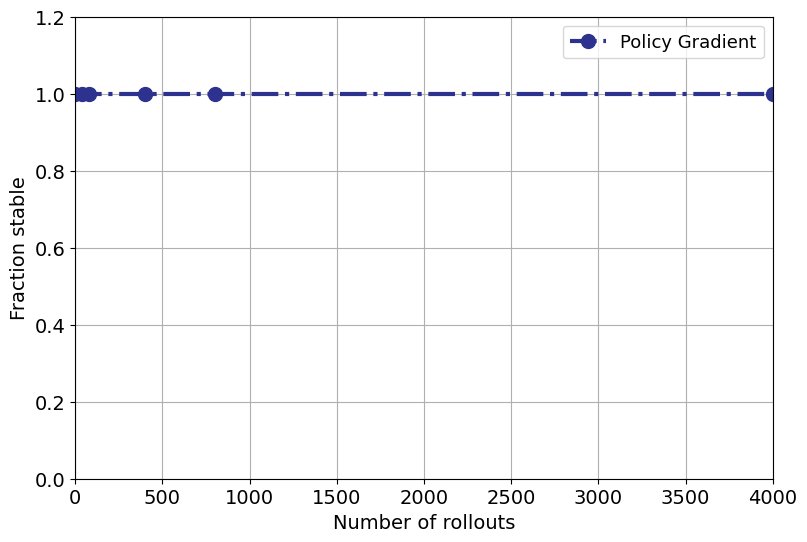

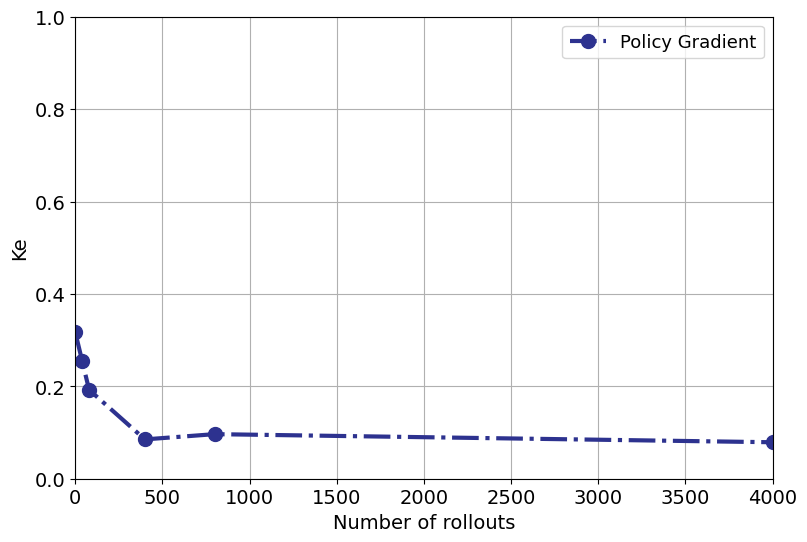

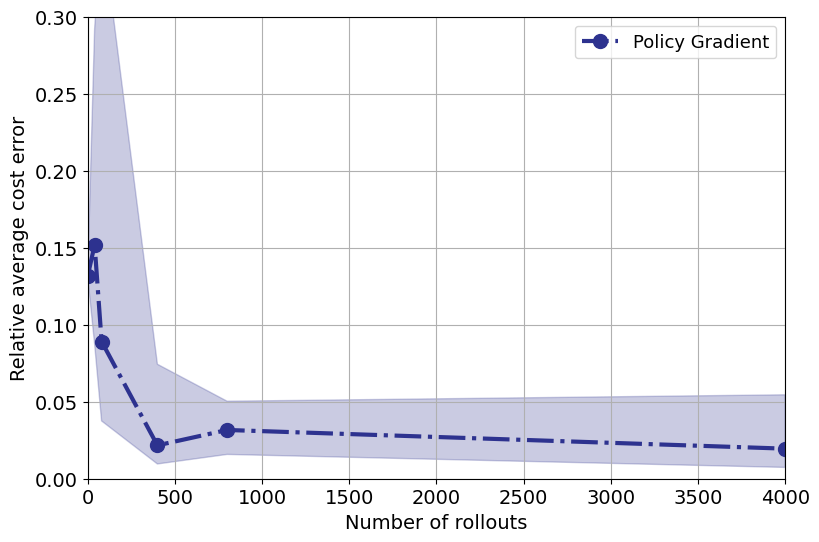

In [21]:
MyPlot = PLTLIB(OPT.J_inf)
J = [meth.J_inf for meth in Methods]
Lab = [meth.name for meth in Methods]
MyPlot.frac_stable(J, n_batch * n_iteration, n_monte_carlo, Lab, 'Number of rollouts')
MyPlot.est_e([meth.Ke for meth in Methods], n_batch * n_iteration, Lab, 'Number of rollouts', "Ke", 1)
MyPlot.relative_inf_cost(J, n_batch * n_iteration, Lab, 'Number of rollouts', uplim=0.3)

We print the estimated controller gain with the policy gradient and compare it with the analytical optimal solution.

In [22]:
print('\nThe optimal k \n', OPT.K)
for meth in Methods:
    print('\nMean of estimated K using', meth.name, '\n', np.mean(meth.K[:, :, :, -1], axis=2))

for meth in Methods:
    print('\nMedian of Ke using', meth.name, np.median(meth.Ke[:, -1]))


The optimal k 
 [[-0.42208244 -1.24392885]]

Mean of estimated K using Policy Gradient 
 [[-0.42614244 -1.28994927]]

Median of Ke using Policy Gradient 0.07893467383651794


The median of $K_e$ will be around $7-14\%$. You can play with the hyper parameters to see if you can get a better result. In general, the plain PG algorithm does not produce good result. To the best of my knowledge, [the convergence of the PG algorithm for LQ problem is only proved for the deterministic LQ problem with stochastic initial conditions.](https://openreview.net/pdf?id=BJDEbngCZ) Usually, PG is combined with other methods (for example dynamic programming which results in actor-critic networks) to produce good results or the baseline should be selected properly.